#----------------------------------------------------------------------

**Covariance and Person's R**

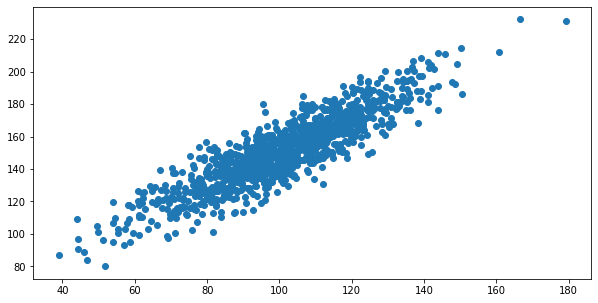

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


In [ ]:

# calculate the Pearson's correlation between two variables
from numpy import mean
from numpy import std
from numpy import cov
from numpy.random import randn
from numpy.random import seed
from matplotlib import pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
# seed random number generator
seed(1)

# prepare data
data1 = 20 * randn(1000) + 100
data2 = data1 + (10 * randn(1000) + 50)

# calculate covariance matrix
covariance = cov(data1, data2)

# calculate Pearson's correlation
corr, _ = pearsonr(data1, data2)

# plot
plt.scatter(data1, data2)
plt.show()

# summarize
print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))
print('Covariance: %.3f' % covariance[0][1])
print('Pearsons correlation: %.3f' % corr)


#----------------------------------------------------------------------

**Regression**
*   linear regression
*   multilinear regression

In [1]:
#-------------------
#Linear Regression
#-------------------

import matplotlib.pyplot as plt
from scipy import stats

#Create the arrays that represent the values of the x and y axis
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

#Execute a method that returns some important key values of Linear Regression
slope, intercept, r, p, std_err = stat.linregress(x, y)

# measure the correlation
corr, _ = stat.pearsonr(x, y)
print('Pearsons correlation: %.3f' % corr)

#Create a function that uses the slope and intercept values to return a new value.
#This new value represents where on the y-axis the corresponding x value will be placed
def myfunc(x):
  return slope * x + intercept

#Run each value of the x array through the function. This will result in a new array with new values for the y-axis
mymodel = list(map(myfunc, x))

#Draw the original scatter plot & the line of linear regression
plt.scatter(x, y)
plt.plot(x, mymodel)
plt.show()

NameError: name 'stat' is not defined

In [ ]:
#Predict Future Values

from scipy import stats

x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

slope, intercept, r, p, std_err = stats.linregress(x, y)

def myfunc(x):
  return intercept + slope * x

speed = myfunc(10)

print(speed)

#----------------------------------------------------------------------

**The coefficient is a factor that describes the relationship with an unknown variable.**
In this case, we can ask for the coefficient value of weight against CO2, and for volume against CO2. The answer(s) we get tells us what would happen if we increase, or decrease, one of the independent values.


The result array represents the coefficient values of weight and volume.

Weight: 0.00755095
Volume: 0.00780526

These values tell us that if the weight increase by 1kg, the CO2 emission increases by 0.00755095g.

And if the engine size (Volume) increases by 1 cm3, the CO2 emission increases by 0.00780526 g.

I think that is a fair guess, but let test it!

We have already predicted that if a car with a 1300cm3 engine weighs 2300kg, the CO2 emission will be approximately 107g.

What if we increase the weight with 1000kg (from 2300 to 3300) what will be the CO2 emission?

Ans: 107.2087328 + (1000 * 0.00755095) = 114.75968

In [ ]:
import pandas
from sklearn import linear_model

df = pandas.read_csv("cars.csv")

X = df[['Weight', 'Volume']]
y = df['CO2']

regr = linear_model.LinearRegression()
regr.fit(X, y)

#predict the CO2 emission of a car where the weight is 2300kg, and the volume is 1300cm3:
predictedCO2 = regr.predict([[2300, 1300]])

print(predictedCO2)

#----------------------------------------------------------------------
**Polynomial regression**

18 cars passing a certain tollboth at different time of the day (x) with different speed (y)

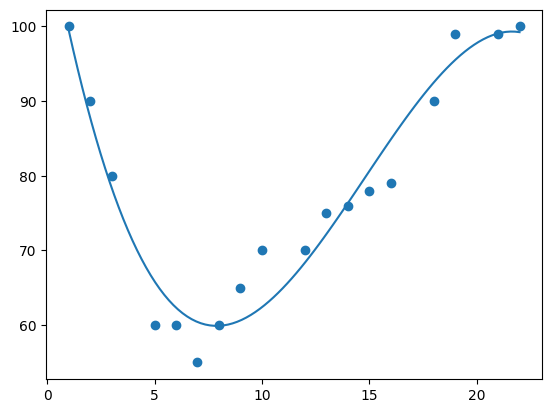

In [2]:
import numpy
import matplotlib.pyplot as plt

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

#NumPy has a method that lets us make a polynomial model
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

#specify how the line will display, we start at position 1, and end at position 22
myline = numpy.linspace(1, 22, 100)

plt.scatter(x, y)
plt.plot(myline, mymodel(myline))
plt.show()